# 1. Libraries import

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from typing import Dict, Set, List
import re
import json

# 2. Load data

In [2]:
data = pd.read_csv("../data/clean/matches-pre2018.csv")
data

,Year,Datetime,Stage,Stadium,City,Home Team Name,Home Team Goals,Away Team Goals,Away Team Name,Win conditions,Attendance,Half-time Home Goals,Half-time Away Goals,Referee,Assistant 1,Assistant 2,RoundID,MatchID,Home Team Initials,Away Team Initials
0,1930,13 Jul 1930 - 15:00,Group 1,Pocitos,Montevideo,France,4,1,Mexico,,4444,3,0,LOMBARDI Domingo (URU),CRISTOPHE Henry (BEL),REGO Gilberto (BRA),201,1096,FRA,MEX
1,1930,13 Jul 1930 - 15:00,Group 4,Parque Central,Montevideo,USA,3,0,Belgium,,18346,2,0,MACIAS Jose (ARG),MATEUCCI Francisco (URU),WARNKEN Alberto (CHI),201,1090,USA,BEL
2,1930,14 Jul 1930 - 12:45,Group 2,Parque Central,Montevideo,Yugoslavia,2,1,Brazil,,24059,2,0,TEJADA Anibal (URU),VALLARINO Ricardo (URU),BALWAY Thomas (FRA),201,1093,YUG,BRA
3,1930,14 Jul 1930 - 14:50,Group 3,Pocitos,Montevideo,Romania,3,1,Peru,,2549,1,0,WARNKEN Alberto (CHI),LANGENUS Jean (BEL),MATEUCCI Francisco (URU),201,1098,ROU,PER
4,1930,15 Jul 1930 - 16:00,Group 1,Parque Central,Montevideo,Argentina,1,0,France,,23409,0,0,REGO Gilberto (BRA),SAUCEDO Ulises (BOL),RADULESCU Constantin (ROU),201,1085,ARG,FRA
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
831,2014,05 Jul 2014 - 13:00,Quarter-finals,Estadio Nacional,Brasilia,Argentina,1,0,Belgium,,68551,1,0,Nicola RIZZOLI (ITA),Renato FAVERANI (ITA),Andrea STEFANI (ITA),255953,300186504,ARG,BEL
832,2014,29 Jun 2014 - 13:00,Round of 16,Estadio Castelao,Fortaleza,Netherlands,2,1,Mexico,,58817,0,0,PROENCA Pedro (POR),MIRANDA Bertino (POR),TRIGO Jose (POR),255951,300186508,NED,MEX
833,2014,29 Jun 2014 - 17:00,Round of 16,Arena Pernambuco,Recife,Costa Rica,1,1,Greece,Costa Rica win on penalties (5 - 3),41242,0,0,Ben WILLIAMS (AUS),CREAM Matthew (AUS),ANAZ Hakan (AUS),255951,300186459,CRC,GRE
834,2014,01 Jul 2014 - 13:00,Round of 16,Arena de Sao Paulo,Sao Paulo,Argentina,1,0,Switzerland,Argentina win after extra time,63255,0,0,ERIKSSON Jonas (SWE),KLASENIUS Mathias (SWE),WARNMARK Daniel (SWE),255951,300186503,ARG,SUI


# 3. Years, final and 3rd place matches

### Years

In [3]:
unique_years = sorted(data["Year"].unique().tolist())
world_cup_years = set(unique_years)

print(f"Number of unique world cup years: {len(world_cup_years)}")
print("World cup years:")
for year in world_cup_years:
    print(f"- {year}")

Number of unique world cup years: 20
World cup years:
- 1930
- 1934
- 1938
- 1950
- 1954
- 1958
- 1962
- 1966
- 1970
- 1974
- 1978
- 1982
- 1986
- 1990
- 1994
- 1998
- 2002
- 2006
- 2010
- 2014


### Final matches

In [4]:
final_matches = data[data["Stage"] == "Final"]
final_matches

,Year,Datetime,Stage,Stadium,City,Home Team Name,Home Team Goals,Away Team Goals,Away Team Name,Win conditions,Attendance,Half-time Home Goals,Half-time Away Goals,Referee,Assistant 1,Assistant 2,RoundID,MatchID,Home Team Initials,Away Team Initials
17,1930,30 Jul 1930 - 14:15,Final,Estadio Centenario,Montevideo,Uruguay,4,2,Argentina,,68346,1,2,LANGENUS Jean (BEL),SAUCEDO Ulises (BOL),CRISTOPHE Henry (BEL),405,1087,URU,ARG
34,1934,10 Jun 1934 - 17:30,Final,Nazionale PNF,Rome,Italy,2,1,Czechoslovakia,Italy win after extra time,55000,0,0,EKLIND Ivan (SWE),BAERT Louis (BEL),IVANCSICS Mihaly (HUN),3490,1134,ITA,TCH
52,1938,19 Jun 1938 - 17:00,Final,Stade Olympique,Colombes,Italy,4,2,Hungary,,45000,3,1,CAPDEVILLE Georges (FRA),WUETHRICH Hans (SUI),KRIST Gustav (TCH),3487,1174,ITA,HUN
100,1954,04 Jul 1954 - 17:00,Final,Wankdorf Stadium,Berne,Germany FR,3,2,Hungary,,62500,2,2,LING William (ENG),ORLANDINI Vincenzo (ITA),GRIFFITHS Benjamin (WAL),3484,1278,FRG,HUN
135,1958,29 Jun 1958 - 15:00,Final,Rasunda Stadium,Solna,Brazil,5,2,Sweden,,49737,2,1,GUIGUE Maurice (FRA),DUSCH Albert (GER),GARDEAZABAL Juan (ESP),3482,1343,BRA,SWE
167,1962,17 Jun 1962 - 14:30,Final,Nacional,Santiago De Chile,Brazil,3,1,Czechoslovakia,,68679,1,1,LATYCHEV Nikolaj (URS),HORN Leo (NED),DAVIDSON Bob (SCO),3480,1463,BRA,TCH
199,1966,30 Jul 1966 - 15:00,Final,Wembley Stadium,London,England,4,2,Germany FR,England win after extra time,96924,0,0,DIENST Gottfried (SUI),BAKHRAMOV Tofik (URS),GALBA Karol (TCH),3478,1633,ENG,FRG
231,1970,21 Jun 1970 - 12:00,Final,Estadio Azteca,Mexico City,Brazil,4,1,Italy,,107412,1,1,GLOECKNER Rudolf (GDR),SCHEURER Ruedi (SUI),COEREZZA Norberto Angel (ARG),3476,1765,BRA,ITA
269,1974,07 July 1974 - 16:00,Final,Olympiastadion,Munich,Netherlands,1,2,Germany FR,,78200,1,2,TAYLOR John (ENG),GONZALEZ ARCHUNDIA Alfonso (MEX),BARRETO RUIZ Ramon (URU),605,2063,NED,FRG
307,1978,25 Jun 1978 - 15:00,Final,El Monumental - Estadio Monumental Antonio Ves...,Buenos Aires,Argentina,3,1,Netherlands,Argentina win after extra time,71483,0,0,GONELLA Sergio (ITA),BARRETO RUIZ Ramon (URU),LINEMAYR Erich (AUT),639,2198,ARG,NED


In [5]:
print(f"Number of final matches: {len(final_matches)}")

final_matches_years = set(sorted(final_matches["Year"].values.tolist()))
print(f"Final matches years:")
for year in final_matches_years:
    print(f"- {year}")

Number of final matches: 19
Final matches years:
- 1930
- 1934
- 1938
- 1954
- 1958
- 1962
- 1966
- 1970
- 1974
- 1978
- 1982
- 1986
- 1990
- 1994
- 1998
- 2002
- 2006
- 2010
- 2014


20 world cups, but 19 final matches, one is missing

In [6]:
final_matches_missing = world_cup_years.difference(final_matches_years)
print("Missing final matches:")
for year in final_matches_missing:
    print(f"- {year}")

Missing final matches:
- 1950


### 3rd place matches

In [7]:
third_place_stages = ["Third place", "Match for third place", "Play-off for third place"]
third_place_matches = data[data["Stage"].isin(third_place_stages)]
third_place_matches

,Year,Datetime,Stage,Stadium,City,Home Team Name,Home Team Goals,Away Team Goals,Away Team Name,Win conditions,Attendance,Half-time Home Goals,Half-time Away Goals,Referee,Assistant 1,Assistant 2,RoundID,MatchID,Home Team Initials,Away Team Initials
33,1934,07 Jun 1934 - 18:00,Match for third place,Giorgio Ascarelli,Naples,Germany,3,2,Austria,,7000,3,1,CARRARO Albino (ITA),CAIRONI Camillo (ITA),ESCARTIN Pedro (ESP),3491,1105,GER,AUT
51,1938,19 Jun 1938 - 17:00,Match for third place,Stade du Parc Lescure,Bordeaux,Brazil,4,2,Sweden,,12000,1,2,LANGENUS Jean (BEL),OLIVE D. (FRA),VALPREDE Ferdinand (FRA),3488,1151,BRA,SWE
99,1954,03 Jul 1954 - 17:00,Match for third place,Hardturm,Zurich,Austria,3,1,Uruguay,,32000,1,1,WYSSLING Paul (SUI),ZSOLT Istvan (HUN),ELLIS Arthur (ENG),3485,1239,AUT,URU
134,1958,28 Jun 1958 - 17:00,Match for third place,Nya Ullevi,Gothenburg,France,6,3,Germany FR,,32483,3,1,BROZZI Juan (ARG),ELLIS Arthur (ENG),LUNDELL Bengt (SWE),3483,1382,FRA,FRG
166,1962,16 Jun 1962 - 14:30,Match for third place,Nacional,Santiago De Chile,Chile,1,0,Yugoslavia,,66697,0,0,GARDEAZABAL Juan (ESP),DUSCH Albert (GER),DOROGI Andor (HUN),3481,1475,CHI,YUG
198,1966,28 Jul 1966 - 19:30,Match for third place,Wembley Stadium,London,Portugal,2,1,Soviet Union,,87696,1,1,DAGNALL Kenneth (ENG),HOWLEY Kevin (ENG),KANDIL Aly Hussein (EGY),3479,1709,POR,URS
230,1970,20 Jun 1970 - 16:00,Match for third place,Estadio Azteca,Mexico City,Germany FR,1,0,Uruguay,,104403,1,0,SBARDELLA Antonio (ITA),MARSCHALL Ferdinand (AUT),AGUILAR ELIZALDE Abel (MEX),3477,1843,FRG,URU
268,1974,06 Jul 1974 - 16:00,Match for third place,Olympiastadion,Munich,Brazil,0,1,Poland,,77100,0,0,ANGONESE Aurelio (ITA),NAMDAR Jafar (IRN),NDIAYE Birame (SEN),264,1984,BRA,POL
306,1978,24 Jun 1978 - 15:00,Match for third place,El Monumental - Estadio Monumental Antonio Ves...,Buenos Aires,Brazil,2,1,Italy,,69659,0,1,KLEIN Abraham (ISR),GONZALEZ ARCHUNDIA Alfonso (MEX),PALOTAI Karoly (HUN),280,2247,BRA,ITA
358,1982,10 Jul 1982 - 20:00,Match for third place,Jose Rico Perez,Alicante,Poland,3,2,France,,28000,2,1,GARRIDO Antonio (POR),RUBIO VAZQUEZ Mario (MEX),LACARNE Belaid (ALG),676,921,POL,FRA


In [8]:
print(f"Number of matches for 3rd place: {len(third_place_matches)}")

third_place_years = set(sorted(third_place_matches["Year"].values.tolist()))
print("3rd place matches:")
for year in third_place_years:
    print(f"- {year}")

Number of matches for 3rd place: 18
3rd place matches:
- 2010
- 1954
- 1986
- 1958
- 1990
- 1962
- 1994
- 1934
- 1966
- 1998
- 1938
- 1970
- 2002
- 2014
- 1974
- 2006
- 1978
- 1982


20 world cups, but 18 matches for 3rd place

In [9]:
third_place_missing = world_cup_years.difference(third_place_years)
print("Missing third place years:")
for year in third_place_missing:
    print(f"- {year}")

Missing third place years:
- 1930
- 1950


# 4. Winners/losers/draw full time

In [10]:
def full_time_outcome(row: pd.DataFrame) -> Dict[str, str]:
    win_lose = {
        "Winner": "",
        "Loser": ""
    }

    home_team = row["Home Team Name"]
    away_team = row["Away Team Name"]
    draw = "Draw"

    home_goals = row["Home Team Goals"]
    away_goals = row["Away Team Goals"]

    if home_goals > away_goals:
        win_lose["Winner"] = home_team
        win_lose["Loser"] = away_team
    elif away_goals > home_goals:
        win_lose["Winner"] = away_team
        win_lose["Loser"] = home_team
    else:
        win_lose["Winner"] = draw
        win_lose["Loser"] = draw

    return win_lose


full_time_outcomes = data.apply(full_time_outcome, axis=1, result_type="expand")
data[["Winner", "Loser"]] = full_time_outcomes

In [11]:
data[["Home Team Name", "Home Team Goals", "Away Team Goals", "Away Team Name", "Winner", "Loser"]]

,Home Team Name,Home Team Goals,Away Team Goals,Away Team Name,Winner,Loser
0,France,4,1,Mexico,France,Mexico
1,USA,3,0,Belgium,USA,Belgium
2,Yugoslavia,2,1,Brazil,Yugoslavia,Brazil
3,Romania,3,1,Peru,Romania,Peru
4,Argentina,1,0,France,Argentina,France
...,...,...,...,...,...,...
831,Argentina,1,0,Belgium,Argentina,Belgium
832,Netherlands,2,1,Mexico,Netherlands,Mexico
833,Costa Rica,1,1,Greece,Draw,Draw
834,Argentina,1,0,Switzerland,Argentina,Switzerland


In [12]:
# Note: "Home Team" is only a label from the match schedule, not the tournament host.

def outcomes(data: pd.DataFrame) -> Dict[str, int]:
    home_wins = (data["Winner"] == data["Home Team Name"]).sum()
    away_wins = (data["Winner"] == data["Away Team Name"]).sum()
    draws = (data["Winner"] == "Draw").sum()

    return {
        "Home Team win": home_wins,
        "Draw": draws,
        "Away Team win": away_wins
    }


def draw_outcomes_bar(outcomes: Dict[str, int], title: str):
    plt.figure(figsize=(8, 5))
    bars = plt.bar(outcomes.keys(), outcomes.values())

    plt.title(title)
    plt.xlabel("Outcome")
    plt.ylabel("Matches")

    plt.bar_label(bars, padding=3)

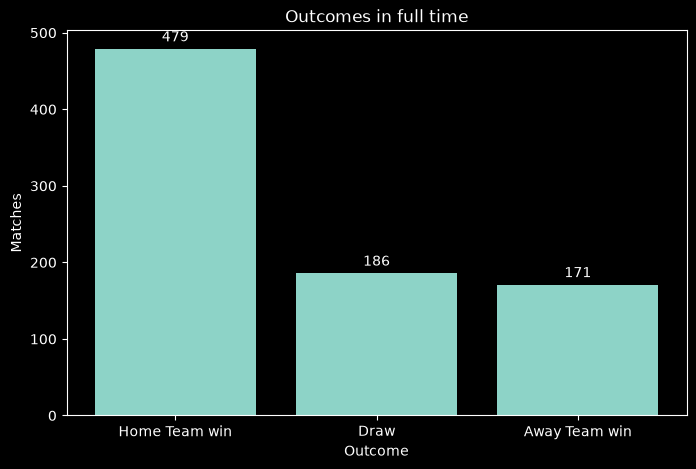

In [13]:
full_time_outcomes = outcomes(data)
draw_outcomes_bar(full_time_outcomes, "Outcomes in full time")

# 5. Win conditions

In [14]:
data["Win conditions"].unique()

<StringArray>
[                                            ' ',
                 'Austria win after extra time ',
                   'Italy win after extra time ',
                  'Brazil win after extra time ',
          'Czechoslovakia win after extra time ',
                 'Hungary win after extra time ',
        'Northern Ireland win after extra time ',
                 'England win after extra time ',
              'Germany FR win after extra time ',
                 'Uruguay win after extra time ',
               'Argentina win after extra time ',
                    ' win on penalties (5 - 4) ',
                 'Belgium win after extra time ',
              'France win on penalties (3 - 4) ',
          'Germany FR win on penalties (4 - 1) ',
             'Belgium win on penalties (4 - 5) ',
                  'France win after extra time ',
                'Cameroon win after extra time ',
 'Republic of Ireland win on penalties (5 - 4) ',
              'Yugoslavia win after 

In [15]:
def parse_win_condition(row):
    condition = str(row["Win conditions"]).strip()

    result = {
        "Winner": row["Winner"],
        "Loser": row["Loser"]
    }

    if not condition:
        return result

    home_team = row["Home Team Name"]
    away_team = row["Away Team Name"]

    winner_match = re.search(
        r"^(.+?)\s+win\s+(?:after extra time|on penalties|after Golden Goal)",
        condition,
        re.IGNORECASE
    )

    if winner_match:
        winner = winner_match.group(1).strip()
    else:
        penalty_match = re.search(
            r"win on penalties\s*\((\d+)\s*-\s*(\d+)\)",
            condition,
            re.IGNORECASE
        )

        if penalty_match:
            home_penalties = int(penalty_match.group(1))
            away_penalties = int(penalty_match.group(2))

            if home_penalties > away_penalties:
                winner = home_team
            elif away_penalties > home_penalties:
                winner = away_team
            else:
                return result

        else:
            home_goals = row["Home Team Goals"]
            away_goals = row["Away Team Goals"]

            if home_goals > away_goals:
                winner = home_team
            elif away_goals > home_goals:
                winner = away_team
            else:
                return result

    if winner == home_team:
        result["Winner"] = home_team
        result["Loser"] = away_team

    elif winner == away_team:
        result["Winner"] = away_team
        result["Loser"] = home_team

    return result

In [16]:
results = data.apply(parse_win_condition, axis=1, result_type="expand")
data[["Winner", "Loser"]] = results

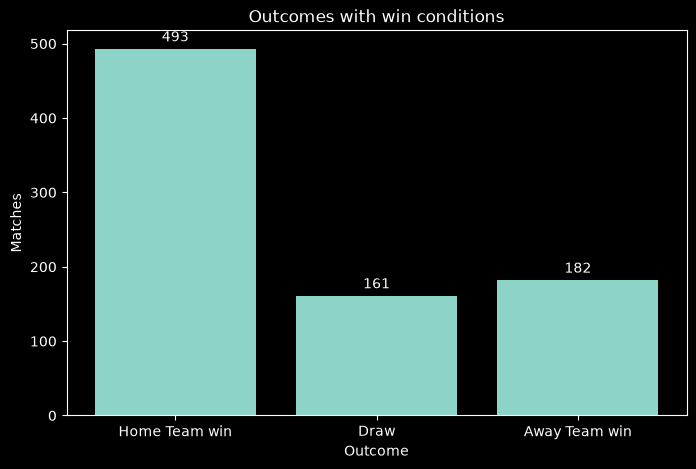

In [17]:
win_cons_outcomes = outcomes(data)
draw_outcomes_bar(win_cons_outcomes, "Outcomes with win conditions")

# 6. Goals

In [18]:
data["Goals"] = data["Home Team Goals"] + data["Away Team Goals"]
data[["Home Team Goals", "Away Team Goals", "Goals"]]

,Home Team Goals,Away Team Goals,Goals
0,4,1,5
1,3,0,3
2,2,1,3
3,3,1,4
4,1,0,1
...,...,...,...
831,1,0,1
832,2,1,3
833,1,1,2
834,1,0,1


# 7. World cup info

In [19]:
def get_rows_per_year(year: int, data: pd.DataFrame) -> pd.DataFrame:
    return data[data["Year"] == year]


def create_map(years: Set[int], values: List) -> Dict:
    return {year: val for year, val in zip(years, values)}

## First, second place

In [20]:
def final_match_row(year: int, data: pd.DataFrame) -> pd.DataFrame:
    rows = get_rows_per_year(year, data)
    return rows[rows["Stage"] == "Final"]


def first_second_place_all(years: Set[int], data: pd.DataFrame) -> Dict:
    teams = []

    for year in years:
        final_row = final_match_row(year, data)

        if final_row.empty:
            teams.append(None)
            continue

        first_place = final_row["Winner"].iloc[0]
        second_place = final_row["Loser"].iloc[0]
        teams.append((first_place, second_place))

    teams_dict = create_map(years, teams)
    # 1950. missing finals
    teams_dict[1950] = ("Uruguay", "Brazil")

    return teams_dict

## Third, fourth place

In [21]:
def third_match_row(year: int, data: pd.DataFrame) -> pd.DataFrame:
    rows = get_rows_per_year(year, data)
    return rows[rows["Stage"].isin(third_place_stages)]


def third_fourth_place_all(years: Set[int], data: pd.DataFrame) -> Dict:
    teams = []

    for year in years:
        third_place_row = third_match_row(year, data)

        if third_place_row.empty:
            teams.append(None)
            continue

        winner = third_place_row["Winner"].iloc[0]
        loser = third_place_row["Loser"].iloc[0]
        teams.append((winner, loser))


    teams_dict = create_map(years, teams)
    # 1930. 1950. missing
    teams_dict[1930] = ("Yugoslavia", "USA")
    teams_dict[1950] = ("Sweden", "Spain")

    return teams_dict

## Total goals

In [22]:
def goals_all(years: Set[int], data: pd.DataFrame) -> Dict:
    goals = []

    for year in years:
        rows = get_rows_per_year(year, data)
        goals_year = rows["Goals"].sum()
        goals.append(goals_year)

    return create_map(years, goals)

## Attendance

In [23]:
def attendance_all(years: Set[int], data: pd.DataFrame) -> Dict:
  attendance = []

  for year in years:
    rows = get_rows_per_year(year, data)
    attendance_year = rows["Attendance"].sum()
    attendance.append(attendance_year)

  return create_map(years, attendance)

## Games

In [24]:
def games_all(years: Set[int], data: pd.DataFrame) -> Dict:
  games = []

  for year in years:
    rows = get_rows_per_year(year, data)
    games_year = len(rows)
    games.append(games_year)

  return create_map(years, games)

## Teams

### IR Iran and Iran same team different name

In [25]:
data.loc[data["Home Team Name"] == "IR Iran", "Home Team Name"] = "Iran"
data.loc[data["Away Team Name"] == "IR Iran", "Away Team Name"] = "Iran"

In [26]:
def teams_all(years: Set[int], data: pd.DataFrame) -> Dict:
    teams = []

    for year in years:
        rows = get_rows_per_year(year, data)
        home_teams = rows["Home Team Name"].unique()
        away_teams = rows["Away Team Name"].unique()

        teams_year = set()
        teams_year.update(home_teams)
        teams_year.update(away_teams)
        teams.append(len(teams_year))

    return create_map(years, teams)


teams_map = teams_all(world_cup_years, data)

for k, v in teams_map.items():
  print(f"Godina {k}: {v}")

Godina 1930: 13
Godina 1934: 16
Godina 1938: 15
Godina 1950: 13
Godina 1954: 16
Godina 1958: 16
Godina 1962: 16
Godina 1966: 16
Godina 1970: 16
Godina 1974: 16
Godina 1978: 16
Godina 1982: 24
Godina 1986: 24
Godina 1990: 24
Godina 1994: 24
Godina 1998: 32
Godina 2002: 32
Godina 2006: 32
Godina 2010: 32
Godina 2014: 32


# 8. Merge

In [27]:
world_cup_df = pd.DataFrame(columns=["Year"])
world_cup_df["Year"] = unique_years
world_cup_df

,Year
0,1930
1,1934
2,1938
3,1950
4,1954
5,1958
6,1962
7,1966
8,1970
9,1974


In [28]:
first_second_map = first_second_place_all(world_cup_years, data)
third_fourth_map = third_fourth_place_all(world_cup_years, data)
goals_map = goals_all(world_cup_years, data)
attendance_map = attendance_all(world_cup_years, data)
games_map = games_all(world_cup_years, data)
teams_map = teams_all(world_cup_years, data)

first_df = pd.DataFrame([
    {"Year": year, "1st place": teams[0]}
    for year, teams in first_second_map.items()
])

second_df = pd.DataFrame([
    {"Year": year, "2nd place": teams[1]}
    for year, teams in first_second_map.items()
])

third_df = pd.DataFrame([
    {"Year": year, "3rd place": teams[0]}
    for year, teams in third_fourth_map.items()
])

fourth_df = pd.DataFrame([
    {"Year": year, "4th place": teams[1]}
    for year, teams in third_fourth_map.items()
])

goals_df = pd.DataFrame(goals_map.items(), columns=["Year", "Goals"])
attendance_df = pd.DataFrame(attendance_map.items(), columns=["Year", "Attendance"])
games_df = pd.DataFrame(games_map.items(), columns=["Year", "Games"])
teams_df = pd.DataFrame(teams_map.items(), columns=["Year", "Teams"])

world_cup_df = (
    first_df
    .merge(second_df, on="Year", how="outer")
    .merge(third_df, on="Year", how="outer")
    .merge(fourth_df, on="Year", how="outer")
    .merge(goals_df, on="Year", how="outer")
    .merge(attendance_df, on="Year", how="outer")
    .merge(games_df, on="Year", how="outer")
    .merge(teams_df, on="Year", how="outer")
    .sort_values("Year")
    .reset_index(drop=True)
)

In [29]:
world_cup_df

,Year,1st place,2nd place,3rd place,4th place,Goals,Attendance,Games,Teams
0,1930,Uruguay,Argentina,Yugoslavia,USA,70,590549,18,13
1,1934,Italy,Czechoslovakia,Germany,Austria,70,363000,17,16
2,1938,Italy,Hungary,Brazil,Sweden,84,375700,18,15
3,1950,Uruguay,Brazil,Sweden,Spain,88,1045246,22,13
4,1954,Germany FR,Hungary,Austria,Uruguay,140,768607,26,16
5,1958,Brazil,Sweden,France,Germany FR,126,819810,35,16
6,1962,Brazil,Czechoslovakia,Chile,Yugoslavia,89,893172,32,16
7,1966,England,Germany FR,Portugal,Soviet Union,89,1563135,32,16
8,1970,Brazil,Italy,Germany FR,Uruguay,95,1603975,32,16
9,1974,Germany FR,Netherlands,Poland,Brazil,97,1865753,38,16


# 9. Additional information

## Average goals per game

In [30]:
avg_goals_df = pd.DataFrame(columns=["Year", "Average Goals"])
avg_goals_df["Year"] = unique_years
avg_goals_df["Average Goals"] = world_cup_df["Goals"] / world_cup_df["Games"]
avg_goals_df

,Year,Average Goals
0,1930,3.888889
1,1934,4.117647
2,1938,4.666667
3,1950,4.000000
4,1954,5.384615
5,1958,3.600000
6,1962,2.781250
7,1966,2.781250
8,1970,2.968750
9,1974,2.552632


## Average attendance

In [31]:
avg_attendance_df = pd.DataFrame(columns=["Year", "Average Attendance"])
avg_attendance_df["Year"] = unique_years
avg_attendance_df["Average Attendance"] = world_cup_df["Attendance"] / world_cup_df["Games"]
avg_attendance_df

,Year,Average Attendance
0,1930,32808.277778
1,1934,21352.941176
2,1938,20872.222222
3,1950,47511.181818
4,1954,29561.807692
5,1958,23423.142857
6,1962,27911.625000
7,1966,48847.968750
8,1970,50124.218750
9,1974,49098.763158


## Most scoring team

In [32]:
home_goals = data[["Year", "Home Team Name", "Home Team Goals"]].rename(
    columns={
        "Home Team Name": "Team",
        "Home Team Goals": "Goals"
    }
)

away_goals = data[["Year", "Away Team Name", "Away Team Goals"]].rename(
    columns={
        "Away Team Name": "Team",
        "Away Team Goals": "Goals"
    }
)

team_goals = pd.concat([home_goals, away_goals])
team_goals = (
    team_goals.groupby(["Year", "Team"])["Goals"]
    .sum()
    .reset_index()
)

most_scoring = team_goals.loc[
    team_goals.groupby("Year")["Goals"].idxmax()
].rename(columns={
    "Team": "Most Scoring Team",
    "Goals": "Team Goals"
})
most_scoring

,Year,Most Scoring Team,Team Goals
0,1930,Argentina,18
22,1934,Italy,12
36,1938,Hungary,15
45,1950,Brazil,22
64,1954,Hungary,27
78,1958,France,23
90,1962,Brazil,14
116,1966,Portugal,17
122,1970,Brazil,19
147,1974,Poland,16


## Most common result

In [33]:
results_df = data[["Year", "Home Team Goals", "Away Team Goals"]].copy()

results_df["Match Result"] = results_df.apply(
    lambda row: f"{max(row['Home Team Goals'], row['Away Team Goals'])}-"
                f"{min(row['Home Team Goals'], row['Away Team Goals'])}",
    axis=1
)

result_occurrences = (
    results_df.groupby(["Year", "Match Result"])
    .size()
    .reset_index(name="Occurrences")
)

most_common_result = (
    result_occurrences.sort_values(
        ["Year", "Occurrences"],
        ascending=[True, False]
    )
    .drop_duplicates(subset="Year")
    .rename(columns={
        "Match Result": "Most Common Result",
        "Occurrences": "Result Occurrences"
    })
    .reset_index(drop=True)
)

most_common_result

,Year,Most Common Result,Result Occurrences
0,1930,1-0,4
1,1934,3-2,5
2,1938,2-1,4
3,1950,2-0,4
4,1954,2-0,3
5,1958,1-0,4
6,1962,3-1,7
7,1966,2-1,9
8,1970,1-0,8
9,1974,1-0,6


In [34]:
world_cup_df = (
    world_cup_df
    .merge(avg_goals_df, on="Year", how="outer")
    .merge(avg_attendance_df, on="Year", how="outer")
    .merge(most_scoring, on="Year", how="outer")
    .merge(most_common_result, on="Year", how="outer")
    .sort_values("Year")
    .reset_index(drop=True)
)
world_cup_df

,Year,1st place,2nd place,3rd place,4th place,Goals,Attendance,Games,Teams,Average Goals,Average Attendance,Most Scoring Team,Team Goals,Most Common Result,Result Occurrences
0,1930,Uruguay,Argentina,Yugoslavia,USA,70,590549,18,13,3.888889,32808.277778,Argentina,18,1-0,4
1,1934,Italy,Czechoslovakia,Germany,Austria,70,363000,17,16,4.117647,21352.941176,Italy,12,3-2,5
2,1938,Italy,Hungary,Brazil,Sweden,84,375700,18,15,4.666667,20872.222222,Hungary,15,2-1,4
3,1950,Uruguay,Brazil,Sweden,Spain,88,1045246,22,13,4.000000,47511.181818,Brazil,22,2-0,4
4,1954,Germany FR,Hungary,Austria,Uruguay,140,768607,26,16,5.384615,29561.807692,Hungary,27,2-0,3
5,1958,Brazil,Sweden,France,Germany FR,126,819810,35,16,3.600000,23423.142857,France,23,1-0,4
6,1962,Brazil,Czechoslovakia,Chile,Yugoslavia,89,893172,32,16,2.781250,27911.625000,Brazil,14,3-1,7
7,1966,England,Germany FR,Portugal,Soviet Union,89,1563135,32,16,2.781250,48847.968750,Portugal,17,2-1,9
8,1970,Brazil,Italy,Germany FR,Uruguay,95,1603975,32,16,2.968750,50124.218750,Brazil,19,1-0,8
9,1974,Germany FR,Netherlands,Poland,Brazil,97,1865753,38,16,2.552632,49098.763158,Poland,16,1-0,6
